In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from rsolvers import RMMGKS

# Toy problem

In [2]:
n = 1000 
np.random.seed(0)
p = 0.01
ground_truth = np.random.binomial(1, p, size=n).astype(np.float64)

noise_stdev = 0.01
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=5, mode="reflect")
#A = jlinops.IdentityOperator((n,n))
noisy_signal = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

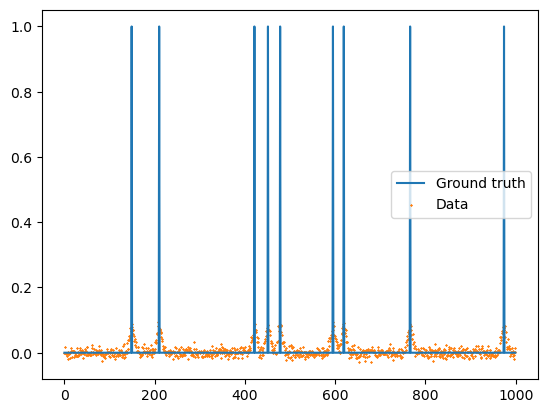

In [3]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization matrix

In [4]:
#Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
#L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
L = jlinops.IdentityOperator((n,n))

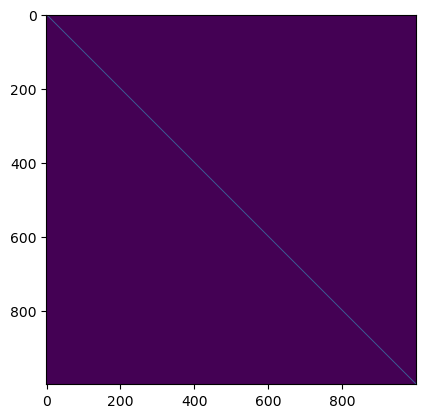

In [5]:
plt.imshow( jlinops.black_box_to_dense(L) )
plt.show()

# Use solver

In [14]:
rmmgks_solver = RMMGKS(A, L, noisy_signal, noise_var=noise_var)
data = rmmgks_solver.solve(n_iter=3000, init_dim=15, kmin=15, kmax=35, epsilon=1e-2, q=1.0, x_true=ground_truth, regparam="dp3")

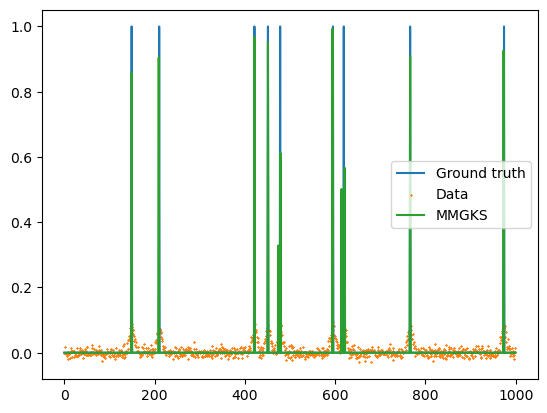

In [15]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.plot(grid, data["x"], label="MMGKS", color="C2")
plt.legend()
plt.show()
plt.show()

In [16]:
data["rre_history"][-1]

0.9860010473872114

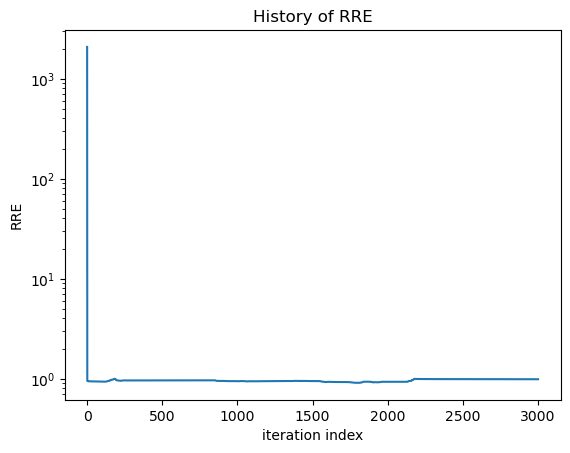

In [17]:
plt.plot(data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

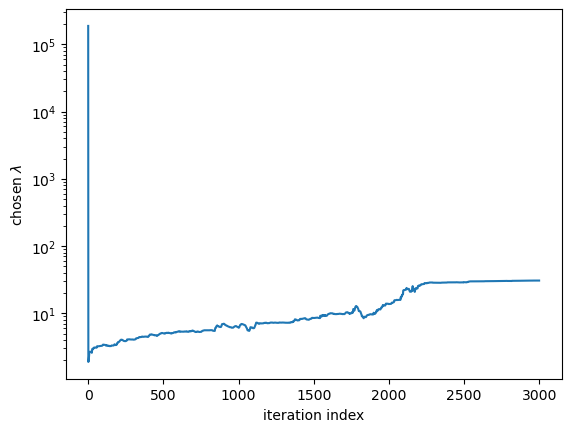

In [18]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

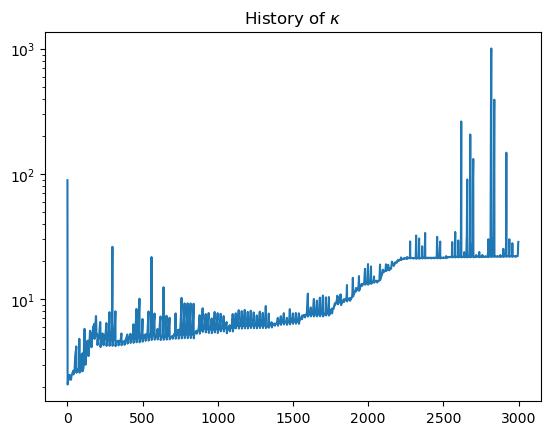

In [19]:
plt.plot(data["cond_ests"])
plt.yscale("log")
plt.title("History of $\\kappa$")
plt.show()

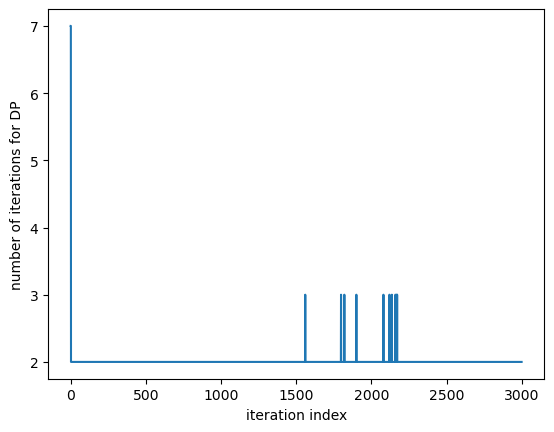

In [20]:
plt.plot(data["dp_cubic_n_iters"])
plt.xlabel("iteration index")
plt.ylabel("number of iterations for DP")
plt.show()